# Exploratory Data Analysis (EDA): KGW Watermark Robustness Prediction
This notebook analyzes the merged dataset (`merged_robustness_dataset.csv`, **10,800 attacked samples** across **600 original documents**) combined from `original_features_combined.csv` and `attack_settings_combined.csv`.

### Key Research Questions Answered:
1. **Baseline Embeddability**: How does initial KGW watermark strength (`initial_z_score`) vary across LLMs (`Qwen2.5-1.5B`, `SmolLM3-3B`, `Llama-3.2-1B`) and text domains (`academic`, `conversational`, `creative`, `instructional`)?
2. **Attack Effectiveness & Semantic Preservation Trade-off**: Which attacks cause the largest absolute (`z_score_drop`) and relative (`relative_z_drop_pct`) drop in z-score, and at what cost to semantic similarity?
3. **Model & Domain Robustness**: Which LLM and writing domain produce watermarks that best survive attacks?
4. **Linguistic Feature Drivers**: Which of the 42 linguistic, syntactic, readability, and entropy features most strongly govern watermark degradation overall and per attack family?


In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
from scipy import stats
try:
    from IPython.display import SVG, display
except ImportError:
    SVG = lambda filename=None, **kw: filename
    display = lambda *a, **kw: None

DATA_DIR = Path(".") if Path("original_features_combined.csv").exists() else Path("src")
PLOTS_DIR = DATA_DIR / "plots"
orig_df = pd.read_csv(DATA_DIR / "original_features_combined.csv")
merged_df = pd.read_csv(DATA_DIR / "merged_robustness_dataset.csv", low_memory=False)

print(f"Original features dataset shape : {orig_df.shape}")
print(f"Merged robustness dataset shape : {merged_df.shape}")
print(f"Unique documents (doc_id)       : {merged_df['doc_id'].nunique()}")
print(f"Attack configurations per doc   : {len(merged_df) // merged_df['doc_id'].nunique()}")
print(f"Models                          : {list(orig_df['model_name'].unique())}")
print(f"Domains                         : {list(orig_df['domain'].unique())}")


Original features dataset shape : (600, 54)
Merged robustness dataset shape : (10800, 82)
Unique documents (doc_id)       : 600
Attack configurations per doc   : 18
Models                          : ['meta-llama/Llama-3.2-1B-Instruct', 'HuggingFaceTB/SmolLM3-3B', 'Qwen/Qwen2.5-1.5B-Instruct']
Domains                         : ['academic', 'conversational', 'creative', 'instructional']


## 1. Initial Watermark Strength & Post-Attack Comparison by Model and Domain
Before measuring attack degradation, we examine how strongly KGW (`gamma=0.25, delta=2.0, z_threshold=4.0`) embeds watermarks in each model and domain, and how much survives after attack.


=== INITIAL WATERMARK STATS BY MODEL ===
                                  docs  mean_initial_z  std_initial_z  median_initial_z  mean_green_frac  initial_detect_rate  mean_word_count  mean_vocab_size  mean_bigram_entropy
model_name                                                                                                                                                                          
HuggingFaceTB/SmolLM3-3B           200         14.4649         4.4586           13.8669           0.4549                0.995          736.365          235.885               8.4951
Qwen/Qwen2.5-1.5B-Instruct         200         19.4899         3.6385           19.3917           0.5174                1.000          715.935          427.405               9.3034
meta-llama/Llama-3.2-1B-Instruct   200         10.4048         4.1203            9.9262           0.4318                0.985          466.555          175.210               8.0674

=== INITIAL WATERMARK STATS BY DOMAIN ===
           

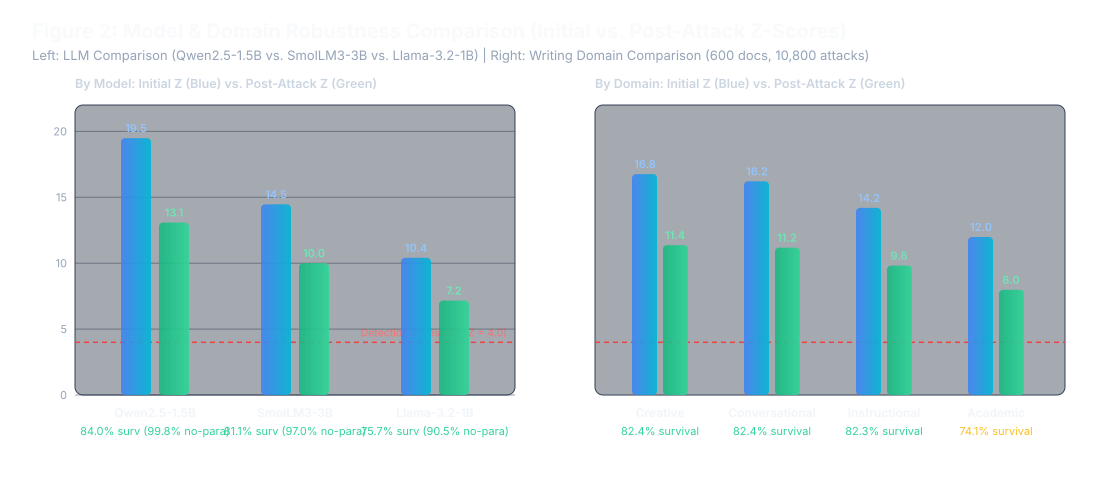

In [2]:
model_init = orig_df.groupby("model_name").agg(
    docs=("doc_id", "count"),
    mean_initial_z=("initial_z_score", "mean"),
    std_initial_z=("initial_z_score", "std"),
    median_initial_z=("initial_z_score", "median"),
    mean_green_frac=("initial_green_fraction", "mean"),
    initial_detect_rate=("initial_detected", "mean"),
    mean_word_count=("word_count", "mean"),
    mean_vocab_size=("vocabulary_size", "mean"),
    mean_bigram_entropy=("bigram_entropy", "mean"),
).round(4)
print("=== INITIAL WATERMARK STATS BY MODEL ===")
print(model_init.to_string())

domain_init = orig_df.groupby("domain").agg(
    docs=("doc_id", "count"),
    mean_initial_z=("initial_z_score", "mean"),
    std_initial_z=("initial_z_score", "std"),
    mean_green_frac=("initial_green_fraction", "mean"),
    initial_detect_rate=("initial_detected", "mean"),
    mean_word_count=("word_count", "mean"),
    mean_mattr=("mattr", "mean"),
    mean_bigram_entropy=("bigram_entropy", "mean"),
).round(4)
print("\n=== INITIAL WATERMARK STATS BY DOMAIN ===")
print(domain_init.to_string())
display(SVG(filename=str(PLOTS_DIR / "02_model_domain_comparison.svg")))


## 2. Which Attacks Affect Watermarks the Most? (Effectiveness vs. Semantic Similarity)
We rank all 18 `(attack_name, intensity)` pairs by mean z-score drop (`z_score_drop = initial_z_score - baseline_z_score`), relative percentage drop (`relative_z_drop_pct`), post-attack survival rate (`baseline_detected == True`), and semantic similarity (`semantic_similarity_cosine`).


=== ATTACK EFFECTIVENESS RANKING (SORTED BY Z-SCORE DROP) ===
                              n  mean_initial_z  mean_attacked_z  mean_z_drop  std_z_drop  mean_rel_drop_pct  survival_rate  removal_rate  semantic_sim
attack_name      intensity                                                                                                                             
humarin          high       600         14.7865           0.7494      14.0371      5.4361            94.9418         0.0167        0.9767        0.8328
                 medium     600         14.7865           1.2069      13.5796      5.2936            91.8011         0.0233        0.9700        0.8421
                 low        600         14.7865           1.4765      13.3101      5.2465            89.8838         0.0483        0.9450        0.8508
helm_typo        high       600         14.7865           6.2635       8.5230      3.6052            57.7283         0.7983        0.1950        0.9249
copy_paste       high     

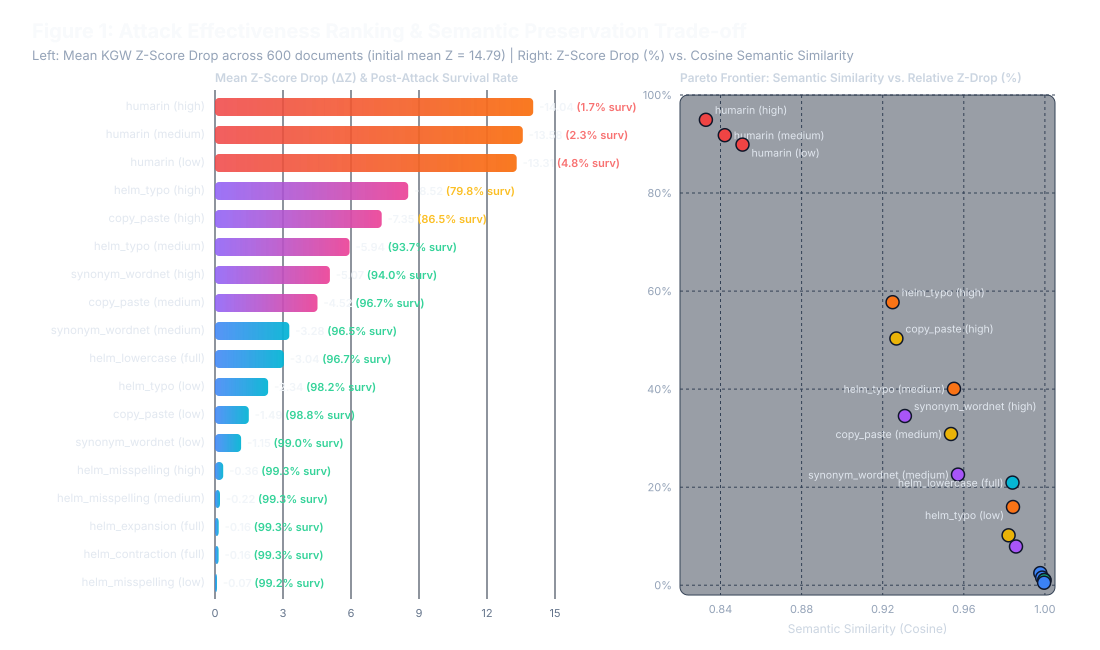

In [3]:
attack_rank = merged_df.groupby(["attack_name", "intensity"]).agg(
    n=("doc_id", "count"),
    mean_initial_z=("initial_z_score", "mean"),
    mean_attacked_z=("baseline_z_score", "mean"),
    mean_z_drop=("z_score_drop", "mean"),
    std_z_drop=("z_score_drop", "std"),
    mean_rel_drop_pct=("relative_z_drop_pct", "mean"),
    survival_rate=("watermark_survived", "mean"),
    removal_rate=("watermark_removed", "mean"),
    semantic_sim=("semantic_similarity_cosine", "mean"),
).round(4).sort_values("mean_z_drop", ascending=False)

print("=== ATTACK EFFECTIVENESS RANKING (SORTED BY Z-SCORE DROP) ===")
print(attack_rank.to_string())
display(SVG(filename=str(PLOTS_DIR / "01_attack_pareto_ranking.svg")))


## 3. Model & Domain Survival Rate Heatmap Across All 18 Attack Configurations
We compare how each model (`Qwen2.5-1.5B`, `SmolLM3-3B`, `Llama-3.2-1B`) and each writing domain (`Creative`, `Conversational`, `Instructional`, `Academic`) survives each of the 18 attack configurations.


=== OVERALL MODEL PERFORMANCE UNDER ATTACK ===
                                  total_attacked  mean_initial_z  mean_attacked_z  mean_z_drop  mean_rel_drop_pct  overall_survival_rate  non_paraphrase_survival  paraphrase_survival  mean_semantic_sim
model_name                                                                                                                                                                                               
HuggingFaceTB/SmolLM3-3B                    3600         14.4649          10.0087       4.4561            31.0281                 0.8114                   0.9700               0.0183             0.9540
Qwen/Qwen2.5-1.5B-Instruct                  3600         19.4899          13.0843       6.4056            33.0623                 0.8403                   0.9977               0.0533             0.9482
meta-llama/Llama-3.2-1B-Instruct            3600         10.4048           7.1649       3.2399            31.6226                 0.7569         

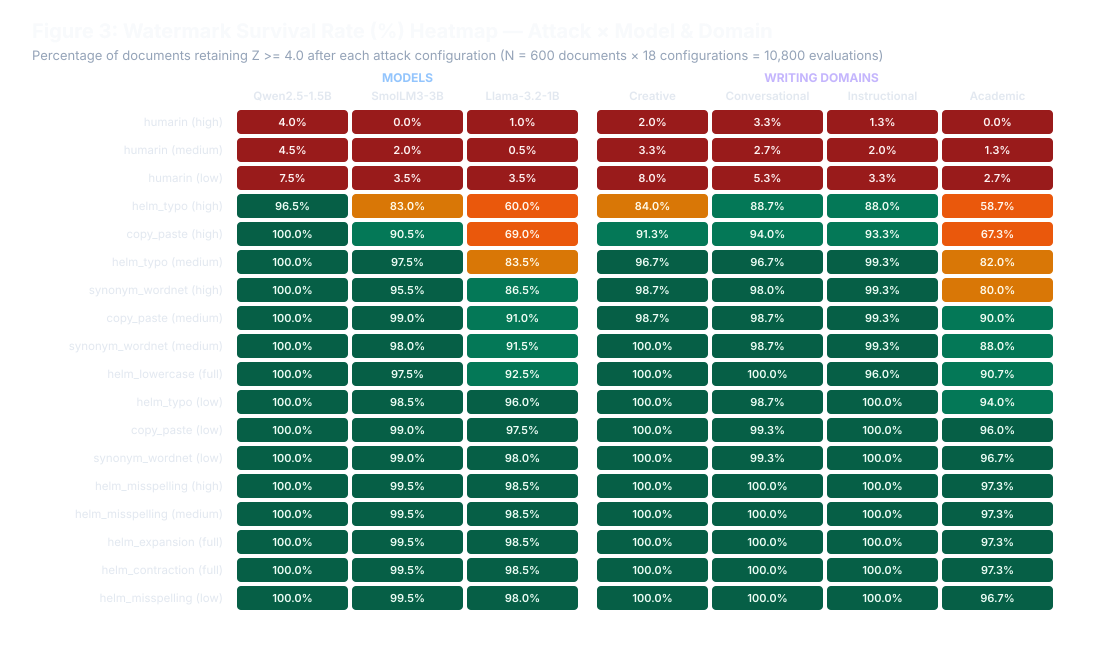

In [4]:
model_perf = merged_df.groupby("model_name").agg(
    total_attacked=("doc_id", "count"),
    mean_initial_z=("initial_z_score", "mean"),
    mean_attacked_z=("baseline_z_score", "mean"),
    mean_z_drop=("z_score_drop", "mean"),
    mean_rel_drop_pct=("relative_z_drop_pct", "mean"),
    overall_survival_rate=("watermark_survived", "mean"),
    non_paraphrase_survival=("watermark_survived", lambda s: s[merged_df.loc[s.index, "attack_name"] != "humarin"].mean()),
    paraphrase_survival=("watermark_survived", lambda s: s[merged_df.loc[s.index, "attack_name"] == "humarin"].mean()),
    mean_semantic_sim=("semantic_similarity_cosine", "mean"),
).round(4)

print("=== OVERALL MODEL PERFORMANCE UNDER ATTACK ===")
print(model_perf.to_string())

domain_perf = merged_df.groupby("domain").agg(
    total_attacked=("doc_id", "count"),
    mean_initial_z=("initial_z_score", "mean"),
    mean_attacked_z=("baseline_z_score", "mean"),
    mean_z_drop=("z_score_drop", "mean"),
    mean_rel_drop_pct=("relative_z_drop_pct", "mean"),
    overall_survival_rate=("watermark_survived", "mean"),
    non_paraphrase_survival=("watermark_survived", lambda s: s[merged_df.loc[s.index, "attack_name"] != "humarin"].mean()),
    mean_semantic_sim=("semantic_similarity_cosine", "mean"),
).round(4)

print("\n=== DOMAIN ROBUSTNESS SUMMARY ===")
print(domain_perf.to_string())
display(SVG(filename=str(PLOTS_DIR / "03_survival_heatmap.svg")))


## 4. Feature Correlation Analysis: Which of the 42 Features Drive Z-Score Drop & Survival?
We analyze correlations at two levels:
1. **Absolute Z-Score Drop (`z_score_drop`)**: Strongly driven by `initial_z_score`, `vocabulary_size`, `word_count`, and `bigram_entropy` (because texts with higher initial z-scores have more room to drop).
2. **Relative Z-Score Drop % (`relative_z_drop_pct`)**: Controls for initial watermark strength to isolate **intrinsic linguistic vulnerability** (which linguistic structures make a watermark easier to disrupt per unit of initial z-score).
3. **Post-Attack Watermark Survival Rate (`watermark_survived`)**: Which features best predict whether `baseline_z_score >= 4.0` after attack.


=== TOP 15 FEATURES BY RELATIVE Z-SCORE DROP (%) CORRELATION ===
                    feature  r_initial_z  r_abs_z_drop  r_rel_z_drop_pct  r_survival_rate  spearman_survival
            vocabulary_size       0.5714        0.6977            0.3631           0.3322             0.3683
second_person_pronoun_ratio       0.1634        0.0627           -0.3546           0.1852             0.3136
                 smog_index      -0.1075       -0.0257            0.3441          -0.2214            -0.2137
        flesch_reading_ease       0.0717       -0.0028           -0.3230           0.1890             0.1828
            adjective_ratio      -0.1236       -0.0468            0.3105          -0.2169            -0.1718
       flesch_kincaid_grade      -0.0672        0.0018            0.3096          -0.1920            -0.2055
          gunning_fog_index      -0.1215       -0.0510            0.3092          -0.2229            -0.2337
             bigram_entropy       0.3301        0.4430         

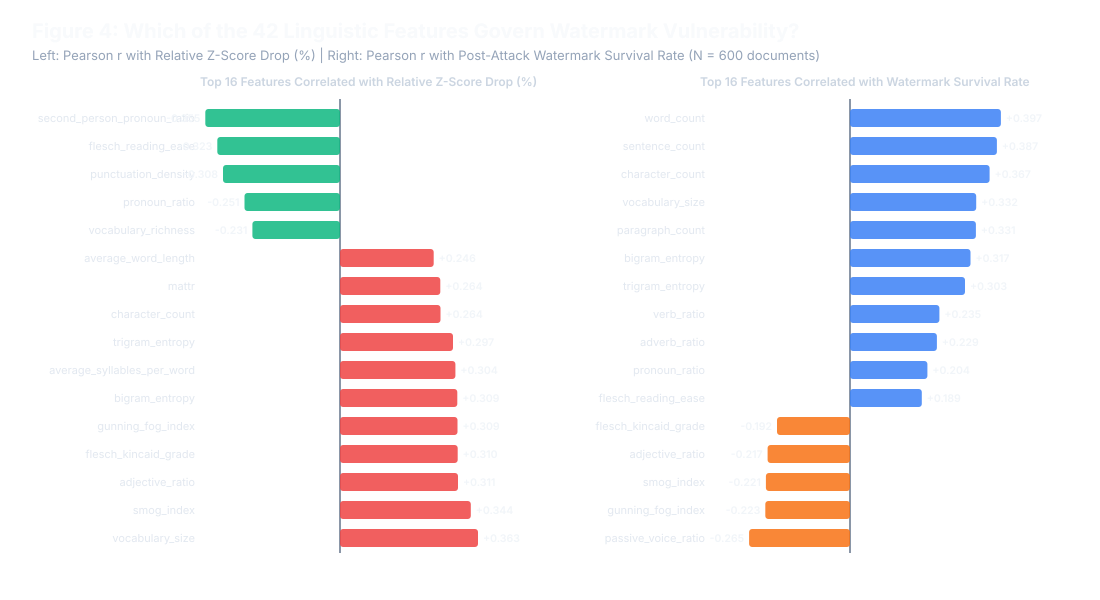

In [5]:
exclude_cols = {
    "doc_id", "file_name", "relative_path", "domain", "model_name",
    "initial_num_tokens_scored", "initial_num_green_tokens",
    "initial_green_fraction", "initial_z_score", "initial_p_value",
    "initial_detected", "initial_detection_threshold"
}
feature_cols = [c for c in orig_df.columns if c not in exclude_cols]

doc_agg = merged_df.groupby("doc_id").agg(
    mean_z_drop=("z_score_drop", "mean"),
    mean_rel_drop_pct=("relative_z_drop_pct", "mean"),
    mean_attacked_z=("baseline_z_score", "mean"),
    survival_rate=("watermark_survived", "mean"),
).reset_index()

doc_level = orig_df.merge(doc_agg, on="doc_id")

rows = []
for f in feature_cols + ["initial_z_score", "initial_green_fraction", "initial_num_tokens_scored"]:
    r_init, _ = stats.pearsonr(doc_level[f], doc_level["initial_z_score"])
    r_abs, p_abs = stats.pearsonr(doc_level[f], doc_level["mean_z_drop"])
    r_rel, p_rel = stats.pearsonr(doc_level[f], doc_level["mean_rel_drop_pct"])
    r_surv, p_surv = stats.pearsonr(doc_level[f], doc_level["survival_rate"])
    rho_surv, _ = stats.spearmanr(doc_level[f], doc_level["survival_rate"])
    rows.append({
        "feature": f,
        "r_initial_z": r_init,
        "r_abs_z_drop": r_abs,
        "r_rel_z_drop_pct": r_rel,
        "r_survival_rate": r_surv,
        "spearman_survival": rho_surv,
    })

corr_table = pd.DataFrame(rows)

print("=== TOP 15 FEATURES BY RELATIVE Z-SCORE DROP (%) CORRELATION ===")
print(corr_table.reindex(corr_table["r_rel_z_drop_pct"].abs().sort_values(ascending=False).index).head(15).round(4).to_string(index=False))

print("\n=== TOP 15 FEATURES BY POST-ATTACK SURVIVAL RATE CORRELATION ===")
print(corr_table.reindex(corr_table["r_survival_rate"].abs().sort_values(ascending=False).index).head(15).round(4).to_string(index=False))
display(SVG(filename=str(PLOTS_DIR / "04_feature_correlations.svg")))


## 5. Attack-Specific Feature Vulnerability Matrix
Different attack mechanisms exploit different linguistic properties. Below, we compute the correlation matrix between linguistic features and relative z-score drop (`relative_z_drop_pct`) for each major attack family at high/full intensity.


=== HUMARIN (high) — Top 5 Linguistic Drivers of Relative Z-Drop ===
  rare_word_ratio                | r_rel_drop = -0.1178 (p=3.87e-03) | r_abs_drop = +0.1077
  vocabulary_size                | r_rel_drop = +0.0816 (p=4.58e-02) | r_abs_drop = +0.5821
  verb_ratio                     | r_rel_drop = +0.0799 (p=5.04e-02) | r_abs_drop = +0.3149
  adjective_ratio                | r_rel_drop = +0.0738 (p=7.09e-02) | r_abs_drop = -0.1107
  technical_vocabulary_ratio     | r_rel_drop = -0.0718 (p=7.88e-02) | r_abs_drop = +0.0269

=== HELM_TYPO (high) — Top 5 Linguistic Drivers of Relative Z-Drop ===
  vocabulary_size                | r_rel_drop = +0.3870 (p=7.17e-23) | r_abs_drop = +0.7513
  smog_index                     | r_rel_drop = +0.3575 (p=1.58e-19) | r_abs_drop = +0.0891
  punctuation_density            | r_rel_drop = -0.3558 (p=2.39e-19) | r_abs_drop = -0.2536
  bigram_entropy                 | r_rel_drop = +0.3453 (p=3.05e-18) | r_abs_drop = +0.5178
  trigram_entropy              

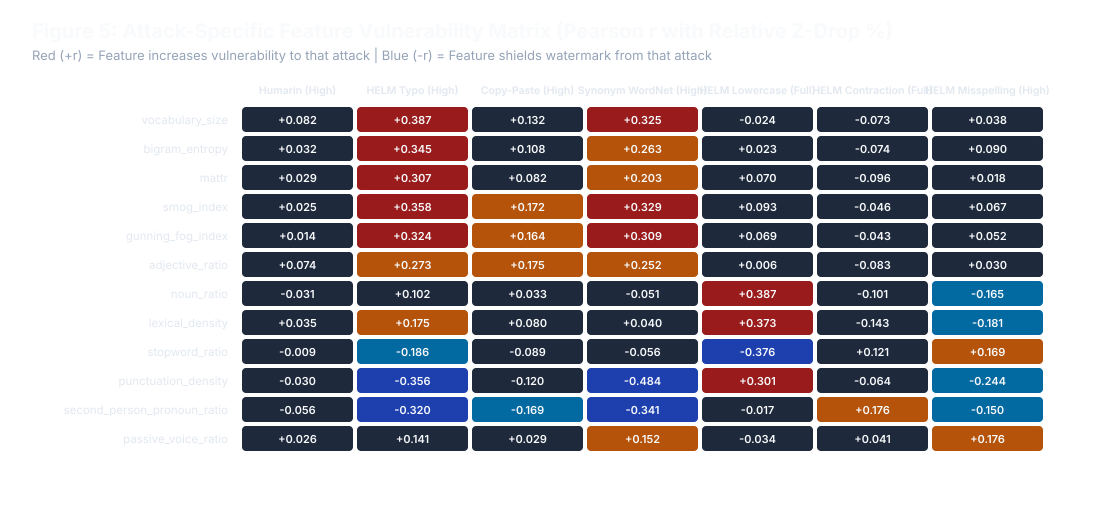

In [6]:
for att in ["humarin", "helm_typo", "copy_paste", "synonym_wordnet", "helm_lowercase", "helm_contraction", "helm_misspelling"]:
    sub = merged_df[merged_df["attack_name"] == att]
    if "high" in sub["intensity"].values:
        sub = sub[sub["intensity"] == "high"]
    att_corrs = []
    for f in feature_cols:
        r_rel, p_val = stats.pearsonr(sub[f], sub["relative_z_drop_pct"])
        r_abs, _ = stats.pearsonr(sub[f], sub["z_score_drop"])
        att_corrs.append((f, r_rel, r_abs, p_val))
    att_corrs.sort(key=lambda x: abs(x[1]), reverse=True)
    print(f"=== {att.upper()} ({sub['intensity'].iloc[0]}) — Top 5 Linguistic Drivers of Relative Z-Drop ===")
    for f, r_rel, r_abs, p_val in att_corrs[:5]:
        print(f"  {f:30s} | r_rel_drop = {r_rel:+.4f} (p={p_val:.2e}) | r_abs_drop = {r_abs:+.4f}")
    print()
display(SVG(filename=str(PLOTS_DIR / "05_attack_feature_matrix.svg")))
